We need the classic imports for this sort of work first:

In [8]:
import numpy as np
import matplotlib.pyplot as plt
import scipy as scp

Now, let's read the data! You can change which light data is being read by changing the `data_dirs` index that's assigned to `selected_dir` (0 is Hydrogen, 1 is Mystery 215, 2 is Mystery 241, 3 is the small light, and 4 is the tube light).

In [10]:
wavelength = []
brightnesses = []
noises = []

data_dirs = ["H", "m215", "m241", "smalllight", "tube", "sunlight"]

# change this line depending on the values to view!
selected_dir = data_dirs[5] 

data_file = 0 # data file count for mean brightness calculation
noise_file = 0 # noise file count for mean brightness calculation

# data files
with open(selected_dir + "/data/files.txt") as selected_data:
    files = selected_data.readlines()
    for filename in files:
        i = 0 # metadata skipper
        brightnesses.append([])
        with open(selected_dir + "/data/" + filename.strip()) as f:
            for line in f: 
                if i < 13:
                    i += 1
                    continue # skip reading metadata lines
                (w, b) = line.strip('\n').split('\t') # remove newline, tab-separated values.
                brightnesses[data_file].append(float(b.replace(',', '.'))) # data recorded in French locale (comma-separated decimals)
        
        data_file += 1

# noise files
if selected_dir != "sunlight":
    with open(selected_dir + "/noise/files.txt") as selected_data:
        files = selected_data.readlines()
        for filename in files:
            i = 0 # metadata skipper
            noises.append([])
            with open(selected_dir + "/noise/" + filename.strip()) as f:
                for line in f: 
                    if i < 13:
                        i += 1
                        continue # skip reading metadata lines
                    (w, b) = line.strip('\n').split('\t') # remove newline, tab-separated values.
                    noises[noise_file].append(float(b.replace(',', '.'))) # data recorded in French locale (comma-separated decimals)

            noise_file += 1

wavelength_array = np.array([i for i in range(350, 1001)])
brightness_array = np.array(brightnesses)

mean_brightness = np.mean(brightness_array, axis=0)
mean_brightness_err = np.std(brightness_array, axis=0)

mean_calibrated = mean_brightness
mean_calibrated_err = mean_brightness_err

if selected_dir != "sunlight":
    noise_array = np.array(noises)
    mean_noise = np.mean(noise_array, axis=0)
    mean_noise_err = np.std(noise_array, axis=0)

    mean_calibrated = mean_brightness - mean_noise
    mean_calibrated_err = np.sqrt(mean_brightness_err ** 2 + mean_noise_err ** 2) # error propagation

Awesome! Now we can plot our data:

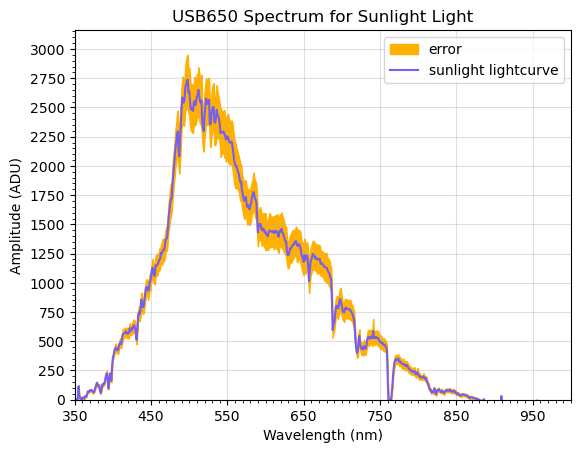

In [11]:
fig, ax = plt.subplots(1)

ax.set_ylim(0, np.max(brightness_array)*1.1)
ax.set_xlim(350, 1000)

ax.set_yticks(np.arange(0, np.max(brightness_array)*1.1, 250))
ax.set_yticks(np.arange(0, np.max(brightness_array)*1.1, 50), minor=True)

ax.set_xticks(np.arange(350, 1000, 100))
ax.set_xticks(np.arange(350, 1005, 10), minor=True)

ax.grid(visible=True, alpha=0.4)

ax.set_ylabel("Amplitude (ADU)")
ax.set_xlabel("Wavelength (nm)")
ax.set_title("USB650 Spectrum for " + selected_dir.capitalize() + " Light")

ax.fill_between(wavelength_array, 
                mean_calibrated - 2*mean_calibrated_err, 
                mean_calibrated + 2*mean_calibrated_err, color='#FFB000', label="error")
ax.plot(wavelength_array, mean_calibrated, color='#785EF0', label=f"{selected_dir} lightcurve")

ax.legend()

The graph above uses $2\sigma$ as the error plot, both so that it is visible in (most) plots and represent the overwhelming majority (96%) of the data distribution.
You might also notice some noise in the 500-700nm range for the mystery gases. The distribution of the noise looks quite similar to the tube light distribution, so we suggest that the noise came from other groups who had the tube light on while we made these measurements. Note that this might also have affected the tube light data itself.

Now, we'll use our **Hydrogen measurements** (which have very clear peaks) to determine the calibration of our spectrometer. this will allow us to apply a systematic shift to the data, as we will know by how much the data is offset by calibration. Do note that any calculations onward are only applicable for the Hydrogen light data. 

We'll estimate the peak locations and values using a local Gaussian distribution and `scipy.optimize.curve_fit` to find the estimated parameters to plot this distribution! The helpers are in the next cell (`neat_print` just prints the results out nicely). We assume that no constant offset is needed for our Gaussian distribution since random noise is cancelled out by subtracting ambient frame values from our measurements. We also use an amplifier power, as we do not use any initial guesses for `scipy.optimize.curve_fit`, which means all parameters are guessed around 1 from the start (and using a power of the amplifier makes the original amplifier value closer to 1, hence easier to get to; the 4th power makes all amplifier values less than 10).

In [4]:
def gauss(x_arr, amp, mu, sd):
    """
    Return Gaussian distribution of x_arr with mean mu, standard 
    deviation sd, and amplifier amp.
    """
    return (amp**4) * (np.exp(-0.5 * ((x_arr - mu)/sd)**2)/(sd * (2*np.pi)**0.5))

def est_fit(func, data, data_range, p0):
    """
    Return tuple of best-fit parameters and covariance of data over data_range using func.
    """
    if func == gauss:
        return scp.optimize.curve_fit(func, 
                                      data_range, 
                                      data, 
                                      bounds=([0, min(data_range), 0], 
                                              [10, max(data_range) - 1, 10]),
                                      maxfev=500000
                                     )
    elif func == pois:
        return scp.optimize.curve_fit(func, 
                                      data_range, 
                                      data, 
                                      bounds=([0, min(data_range), 0], 
                                              [10, max(data_range) - 1, 1000]),
                                      p0=p0,
                                      maxfev=500000
                                     )

def neat_print(fit):
    """
    Print fit parameters obtained with est_fit neatly.
    """
    print("Amp: " + str(round(fit[0], 4)) + 
      "\n Mu: " + str(round(fit[1] + 350, 4)) + 
      "\tnm\n SD: " + str(round(fit[2], 4)) + "\tnm\n")

Now, let's estimate our peaks! We expect peaks around 410.2, 434.0, 486.1, and 656.3 nm, so we'll take 20 indices around them from our data to estimate where our measured peaks are:

In [12]:
ranges = (np.array([50, 74, 126, 296]), np.array([71, 95, 147, 317]))
expected = np.array([410.2, 434.0, 486.1, 656.3])

params = [] 
covs = []

for i in range(len(ranges[0])):
    peak = mean_calibrated[ranges[0][i]:ranges[1][i]]
    index = np.arange(ranges[0][i], ranges[1][i], 1)
    
    (fit, cov_matrix) = est_fit(gauss, peak, index, [])
    
    
    print(f"PEAK {str(i+1)} (expected: {expected[i]} nm)")
    neat_print(fit)
    
    params.append(fit)
    covs.append(cov_matrix)
    
print(f'Covariance matrix for PEAK 1: \n{covs[0]}\n' +
      f'These values are exceptionally high (others are in 10^-2 to 10^-8 range) \n' +
      f'    -> Perhaps is it more interesting to try another distribution, such as Poisson?')

PEAK 1 (expected: 410.2 nm)
Amp: 1.907
 Mu: 410.463	nm
 SD: 0.254	nm

PEAK 2 (expected: 434.0 nm)
Amp: 2.2707
 Mu: 433.9933	nm
 SD: 0.5814	nm

PEAK 3 (expected: 486.1 nm)
Amp: 4.4702
 Mu: 486.1463	nm
 SD: 0.4589	nm

PEAK 4 (expected: 656.3 nm)
Amp: 8.3484
 Mu: 656.3819	nm
 SD: 0.5428	nm

Covariance matrix for PEAK 1: 
[[ 6.41363195e+08  3.48375876e+07 -1.19648211e+08]
 [ 3.48375876e+07  1.89230926e+06 -6.49905554e+06]
 [-1.19648211e+08 -6.49905554e+06  2.23207294e+07]]
These values are exceptionally high (others are in 10^-2 to 10^-8 range) 
    -> Perhaps is it more interesting to try another distribution, such as Poisson?


In [13]:
def pois(x_arr, amp, mu, offset):
    """
    Return Poisson distribution using integer array x_arr and mean mu, applying a horizontal offset and amplifier.
    """
    result = (amp**2) * (np.exp(-mu, dtype=np.float128) \
                            * np.power(mu, (x_arr - offset), dtype=np.float128))
    
    # division by factorial, implemented by integer 
    for i in range(0, len(result) - 1):
        for j in range(1, int(x_arr[i] - offset) + 1):
            result[i] /= j
    return result

# the mean is suggested to be the index right after the peak because of the skewed aspect of the Poisson distribution
# for peak 0, this is estimated to be 411nm, i.e. index 61

peak = mean_calibrated[ranges[0][0]:ranges[1][0]]
index = np.arange(ranges[0][0], ranges[1][0], 1)

temp_index = index - 59

params[0], covs[0] = est_fit(pois, peak, temp_index, p0=[10, 1, 59])

print(peak)

print(f'Estimations:\n{params[0]}\n\n Covariance Matrix:\n{covs[0]}\n')

print("Not that much better, especially since that doesn't plot well at all - the parameters don't make any sense!\n")

[ 0.024  0.522  0.03   0.41   0.87   0.332  0.984 -1.148  0.526 -0.252
  3.942  2.222 -0.436  1.416  0.596  0.412 -0.316 -0.13  -0.158  0.558
  1.782]
Estimations:
[  8.03045336   1.02324033 161.83016238]

 Covariance Matrix:
[[ 2.09989538e+03  3.36439254e+00 -1.93709805e+02]
 [ 3.36439254e+00  5.39768915e-03 -3.10356330e-01]
 [-1.93709805e+02 -3.10356330e-01  1.78692182e+01]]

Not that much better, especially since that doesn't plot well at all - the parameters don't make any sense!



Let's try to look at the points themselves on all plots to see what could be going wrong.

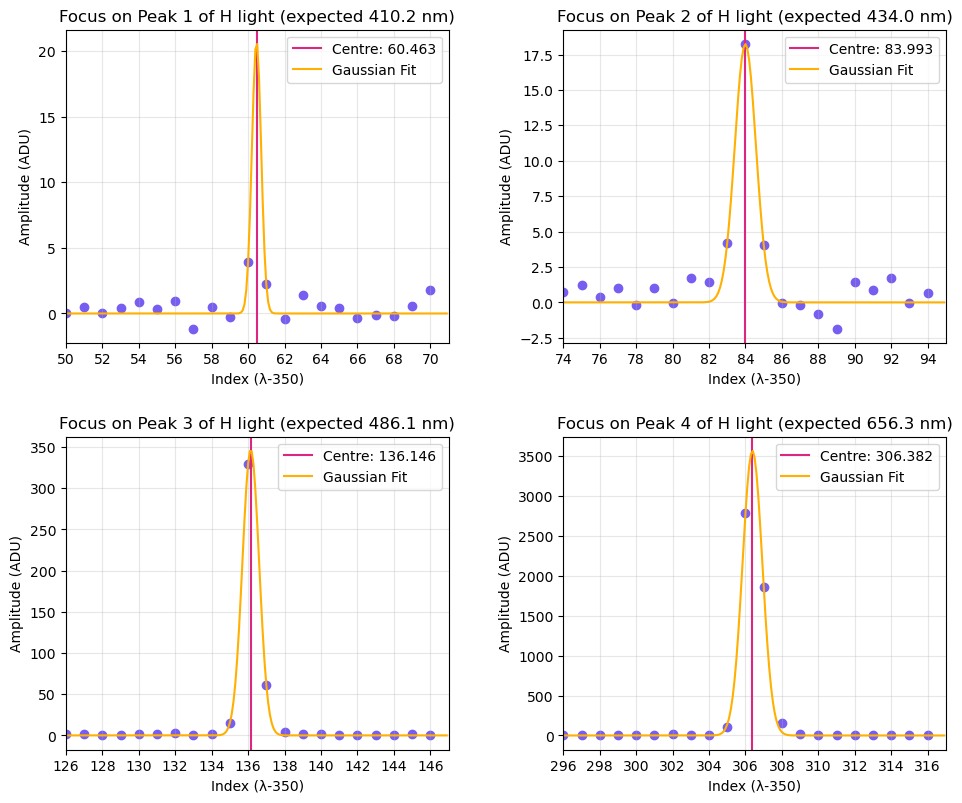

In [20]:
# refit Gaussian over peak 0
peak = mean_calibrated[ranges[0][0]:ranges[1][0]]
index = np.arange(ranges[0][0], ranges[1][0], 1)
    
(params[0], covs[0]) = est_fit(gauss, peak, index, [])

# end of refitting

fig, axs = plt.subplots(2, 2)
plt.subplots_adjust(bottom=0, right=1.5, top=1.5, wspace=0.3, hspace=0.3)

peak_indices = []
peak_mags = []

axs[0][0].set_xlim(50, 71)
axs[0][1].set_xlim(74, 95)
axs[1][0].set_xlim(126, 147)
axs[1][1].set_xlim(296, 317)

for i in range(len(ranges[0])):
    peak = mean_calibrated[ranges[0][i]:ranges[1][i]]
    index = np.arange(ranges[0][i], ranges[1][i], 1)
    
    axs[i//2][i%2].scatter(index, peak, color="#785EF0")
    
    amp = params[i][0]
    mu = params[i][1]
    sd = params[i][2]
    
    axs[i//2][i%2].axvline(mu, color="#DC267F", label=f"Centre: {round(mu, 3)}")

    axs[i//2][i%2].set_xticks([i for i in index if i%2 == 0])
    axs[i//2][i%2].grid(alpha=0.3)

    axs[i//2][i%2].set_title(f"Focus on Peak {i+1} of H light (expected {expected[i]} nm)")
    axs[i//2][i%2].set_xlabel("Index (λ-350)")
    axs[i//2][i%2].set_ylabel("Amplitude (ADU)")
    
    overplot_range = np.arange(ranges[0][i], ranges[1][i], 0.1)
    axs[i//2][i%2].plot(overplot_range, gauss(overplot_range, amp, mu, sd), color='#FFB000', label='Gaussian Fit')

    axs[i//2][i%2].legend()

    peak_indices.append(mu)
    peak_mags.append(gauss(mu, amp, mu, sd))

Most of the points in the last 3 peaks seem to clearly show some sort of Gaussian, but that's not the case with peak 0. The culprits might be the points at indices 59 and 61, that drop much more harshly compared to their neighbours. Perhaps we could get a better Gaussian fit if we omitted these points.

In [21]:
peak0 = mean_calibrated[50:57]
peak1 = mean_calibrated[58:59]
peak2 = mean_calibrated[60:62]
peak3 = mean_calibrated[64:71]

peak = np.concatenate((peak0, peak1, peak2, peak3))

print(peak)

index0 = np.arange(50, 57, 1)
index1 = np.arange(58, 59, 1)
index2 = np.arange(60, 62, 1)
index3 = np.arange(64, 71, 1)

index = np.concatenate((index0, index1, index2, index3))

print(index)
    
params[0], covs[0] = est_fit(gauss, peak, index, [1.65, 60.2, 0.7])
    
    
print(f"PEAK 0 (expected: {expected[0]} nm)")
neat_print(params[0])

params.append(fit)
covs.append(cov_matrix)
    
print(f'Covariance matrix for PEAK 1: \n{covs[0]}\n')

[ 0.024  0.522  0.03   0.41   0.87   0.332  0.984  0.526  3.942  2.222
  0.596  0.412 -0.316 -0.13  -0.158  0.558  1.782]
[50 51 52 53 54 55 56 58 60 61 64 65 66 67 68 69 70]
PEAK 0 (expected: 410.2 nm)
Amp: 1.7631
 Mu: 409.9542	nm
 SD: 0.9774	nm

Covariance matrix for PEAK 1: 
[[ 0.01193328 -0.01649923  0.01879368]
 [-0.01649923  0.08838171 -0.01994043]
 [ 0.01879368 -0.01994043  0.05435875]]



This is a much stronger fit, implying that the data had some "outlier" values. This issue is also certainly linked to the fact that the signal-to-noise ratio (S/N) becoming particularly low, as the points near the peak reach between 2-4 ADUs while non-peak (= noise) values are usually in the -2 to 1 ADU.<br>
The peak we find is also particularly far from the expected peak wavelength relative to otehr peaks, which is likely also because of the S/N ratio.

Now, we can overplot our distributions over the index ranges of our peaks and estimate the peak brightness:

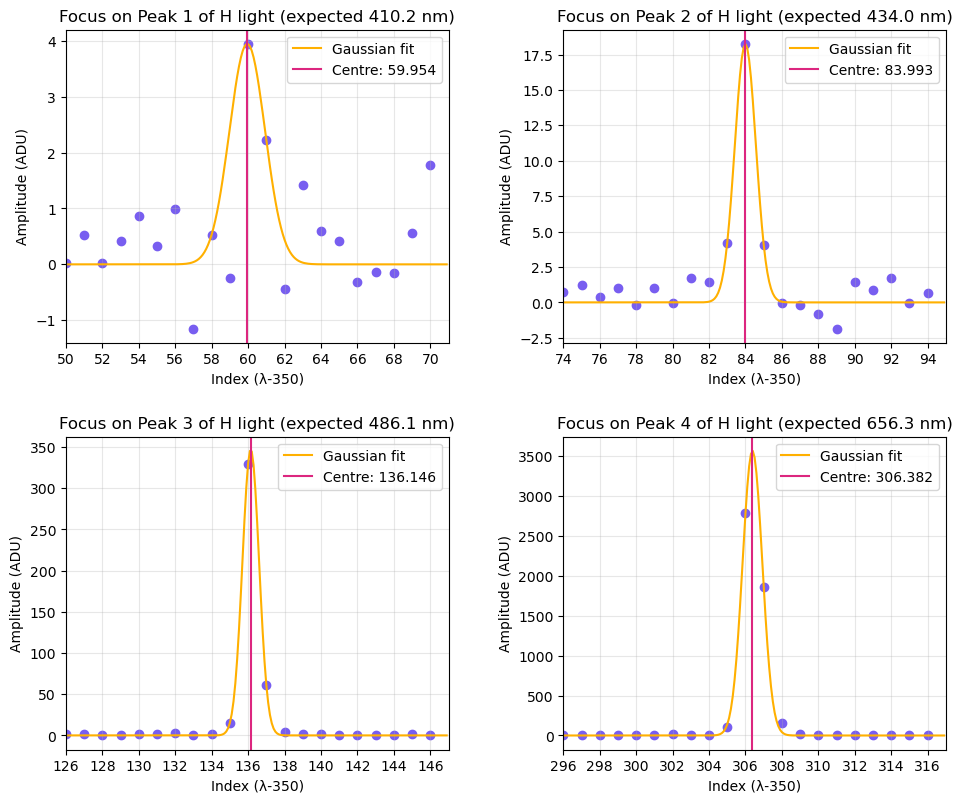

In [22]:
fig, axs = plt.subplots(2, 2)
plt.subplots_adjust(bottom=0, right=1.5, top=1.5, wspace=0.3, hspace=0.3)

peak_indices = []
peak_mags = []

axs[0][0].set_xlim(50, 71)
axs[0][1].set_xlim(74, 95)
axs[1][0].set_xlim(126, 147)
axs[1][1].set_xlim(296, 317)

for i in range(len(ranges[0])):
    peak = mean_calibrated[ranges[0][i]:ranges[1][i]]
    index = np.arange(ranges[0][i], ranges[1][i], 1)
    
    axs[i//2][i%2].scatter(index, peak, color="#785EF0")
    
    amp = params[i][0]
    mu = params[i][1]
    
    """
    if i == 0: # special Poisson overplot for the first peak
        overplot_range = np.arange(ranges[0][i], ranges[1][i], 1) # pois only supports integer x_arr values

        offset = params[i][2]
        
        print(pois(overplot_range, amp, mu, offset))
        
        axs[i//2][i%2].plot(overplot_range, pois(overplot_range, amp, mu, offset), color="#FFB000", label="Poisson fit")
        
    else:

        overplot_range = np.arange(ranges[0][i], ranges[1][i], 0.1)
        
        sd = params[i][2]
        axs[i//2][i%2].plot(overplot_range, gauss(overplot_range, amp, mu, sd), color="#FFB000", label="Gaussian fit")
    """
    overplot_range = np.arange(ranges[0][i], ranges[1][i], 0.1)
        
    sd = params[i][2]
    axs[i//2][i%2].plot(overplot_range, gauss(overplot_range, amp, mu, sd), color="#FFB000", label="Gaussian fit")
    axs[i//2][i%2].axvline(mu, color="#DC267F", label=f"Centre: {round(mu, 3)}")

    axs[i//2][i%2].set_xticks([i for i in index if i%2 == 0])
    axs[i//2][i%2].grid(alpha=0.3)

    axs[i//2][i%2].set_title(f"Focus on Peak {i+1} of H light (expected {expected[i]} nm)")
    axs[i//2][i%2].set_xlabel("Index (λ-350)")
    axs[i//2][i%2].set_ylabel("Amplitude (ADU)")

    axs[i//2][i%2].legend()

    peak_indices.append(mu)
    peak_mags.append(gauss(mu, amp, mu, sd))

We need to reshift our index values to wavelength values in nm, and can plot our peak wavelength and estimated magnitude!

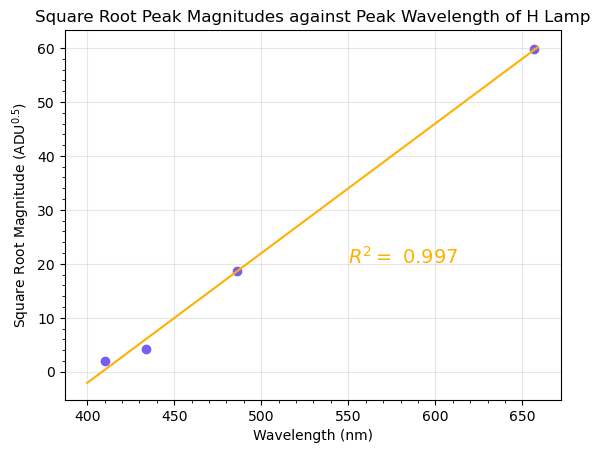

In [23]:
def least_squares(x_arr, y_arr, N):
    """
    Return a tuple of gradient (m) and constant (c) for linear regression using values from arrays x_arr and y_arr.
    Both arrays contain N entries.
    """    
    x_arr2 = x_arr ** 2
    xy_arr = x_arr * y_arr
    
    sum_x = np.sum(x_arr)
    sum_y = np.sum(y_arr)
    sum_x2 = np.sum(x_arr2)
    sum_xy = np.sum(xy_arr)
    
    det = (N * sum_x2 - sum_x ** 2)**(-1)

    m = det * (sum_xy * N - sum_y * sum_x)
    c = det * (sum_y * sum_x2 - sum_xy * sum_x)

    return (m, c)

def r_squared(x_arr, y_arr):
    """
    Return the R-squared value of a best-fit line of y_arr against x_arr, using covariance results from numpy.cov.
    """
    sumx_2, sumxy_2, sumy_2 = (np.cov(x_arr, y_arr, bias=True)[0][0], 
                               np.cov(x_arr, y_arr, bias=True)[0][1], 
                               np.cov(x_arr, y_arr, bias=True)[1][1])
    
    if sumx_2 * sumy_2 == 0: # zero denominator of R^2
        return 0
    else:
        return (sumxy_2 ** 2) / (sumx_2 * sumy_2)

# correct indices to wavelengths. the if statement ensures this calculation is only done once
# if running the cell multiple times
for i in range(len(peak_indices)):
    if peak_indices[i] <350:
        peak_indices[i] += 350

peak_wavelengths = np.array(peak_indices)
peak_ests = np.array(peak_mags)

r2 = r_squared(peak_wavelengths, peak_ests ** 0.5)

# perform least squares linear regression on the data
(m, c) = least_squares(peak_wavelengths, peak_ests ** 0.5, 4)
lin_range = np.arange(400, 660, 1)

fig, ax = plt.subplots(1)
ax.scatter(peak_wavelengths, peak_ests ** 0.5, color="#785EF0")
ax.plot(lin_range, m * lin_range + c, color="#FFB000")

ax.set_title("Square Root Peak Magnitudes against Peak Wavelength of H Lamp")

ax.set_ylabel("Square Root Magnitude (ADU$^{0.5}$)")
ax.set_xlabel("Wavelength (nm)")

ax.set_xticks(np.arange(400, 650, 10), minor=True)
ax.set_yticks(np.arange(0, 60, 2), minor=True)

ax.text(550, 20, f'$R^2 =$ {round(r2, 3)}', fontsize=14, color="#FFB000")
ax.grid(visible=True, alpha=0.3)
plt.show()

It is also useful to try to replot this graph omitting peak 0 because of its inconsistency, to check for any significant changes in the fit.

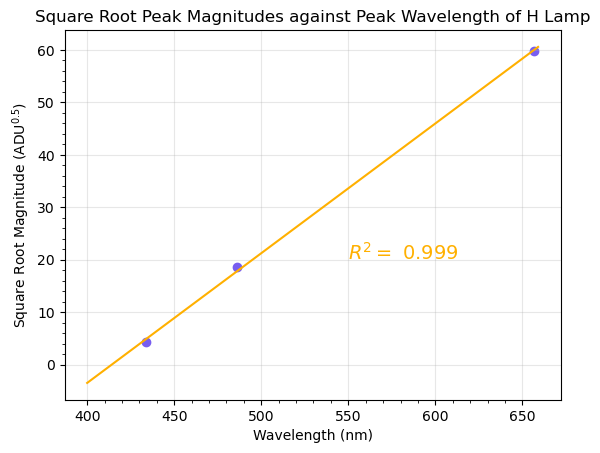

In [99]:
for i in range(len(peak_indices)):
    if peak_indices[i] <350:
        peak_indices[i] += 350

peak_wavelengths3 = np.array(peak_indices[1:4])
peak_ests3 = np.array(peak_mags[1:4])

r2 = r_squared(peak_wavelengths3, peak_ests3 ** 0.5)

# perform least squares linear regression on the data
(m3, c3) = least_squares(peak_wavelengths3, peak_ests3 ** 0.5, 3)

lin_range = np.arange(400, 660, 1)

fig, ax = plt.subplots(1)
ax.scatter(peak_wavelengths3, peak_ests3 ** 0.5, color="#785EF0")
ax.plot(lin_range, m3 * lin_range + c3, color="#FFB000")

ax.set_title("Square Root Peak Magnitudes against Peak Wavelength of H Lamp")

ax.set_ylabel("Square Root Magnitude (ADU$^{0.5}$)")
ax.set_xlabel("Wavelength (nm)")

ax.set_xticks(np.arange(400, 650, 10), minor=True)
ax.set_yticks(np.arange(0, 60, 2), minor=True)

ax.text(550, 20, f'$R^2 =$ {round(r2, 3)}', fontsize=14, color="#FFB000")
ax.grid(visible=True, alpha=0.3)
plt.show()